# Optics matching with Xopt

This example follows PyTutorial 4, replacing SciPy's minimizer with **Xopt**, the optimization library developed at SLAC. The lattice, beam, and matching merit are the same.

If needed, run `%pip install xopt` in a separate cell and restart the kernel. RF-Track must also be installed. See the [Xopt documentation](https://xopt.xopt.org/) for more examples.

At the end we compare the result with `scipy.minimize`, first on the simulated beam and then with measurement noise, as on a real machine.

In [1]:
import os
from time import perf_counter
import RF_Track as rft
import numpy as np
import matplotlib.pyplot as plt
import xopt

[RF-Track] Could not check for updates.



RF-Track, version 2.7.3

Copyright (C) 2016-2026 CERN, Geneva, Switzerland. All rights reserved.

Author and contact:
 Andrea Latina <andrea.latina@cern.ch>
 BE-ABP Group
 CERN
 CH-1211 GENEVA 23
 SWITZERLAND

This software is distributed under a CERN proprietary software
license in the hope that it will be useful, but WITHOUT ANY WARRANTY;
not even for MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE.

See the COPYRIGHT and LICENSE files at the top-level directory of
the RF-Track download area: https://gitlab.cern.ch/rf-track

RF-Track was compiled with GSL-2.8 and fftw-3.3.11



## Bunch parameters

In [2]:
# Bunch parameters
mass = rft.electronmass # MeV/c^2
charge = -1 # single-particle charge, in units of e
population = 1*rft.nC # number of real particles per bunch
Pc = 5 # reference momentum, MeV/c
P_Q = Pc / charge # MV/c, reference rigidity

## FODO cell parameters

In [3]:
# FODO cell parameters
Lcell = 2 # m
Lquad = 0.2 # m
Ldrift = Lcell/2 - Lquad # m

mu = np.deg2rad(90) # deg
k1L = np.sin(mu/2) / (Lcell/4) # 1/m

strength = k1L * P_Q # MeV/m

## Define the elements

In [4]:
# Half a focusing quadrupole
Qf = rft.Quadrupole(Lquad/2, strength/2)

# A full, defocusing, quadrupole
QD = rft.Quadrupole(Lquad, -strength)

# The Drift
Dr = rft.Drift(Ldrift)

# Define a lattice with 10 FODO cells

In [5]:
# Define the FODO cell
FODO = rft.Lattice()
FODO.append(Qf)
FODO.append(Dr)
FODO.append(QD)
FODO.append(Dr)
FODO.append(Qf)

# Create the full lattice by repeating the FODO cell 10 times
L = rft.Lattice()
for _ in range(10):
    L.append(FODO)

# ...and a bunch

In [6]:
# Define Twiss parameters
Twiss = rft.Bunch6d_twiss()
Twiss.emitt_x = 0.001 # mm.mrad, normalized emittances
Twiss.emitt_y = 0.001 # mm.mrad
Twiss.alpha_x = 0.0
Twiss.alpha_y = 0.0
Twiss.beta_x = Lcell * (1 + np.sin(mu/2)) / np.sin(mu) # m
Twiss.beta_y = Lcell * (1 - np.sin(mu/2)) / np.sin(mu) # m

# Create the bunch
B0 = rft.Bunch6d_QR (mass, population, charge, Pc, Twiss, 1000)

In [7]:
print(Twiss.beta_x)
print(Twiss.beta_y)

3.414213562373095
0.5857864376269051


# Then, we can perform tracking

In [8]:
L.set_tt_nsteps(1000)
B1 = L.track(B0)

We can query the lattice to obtain, for example, the Twiss parameters and emittance.

In [9]:
T = L.get_transport_table('%S %beta_x %beta_y %emitt_x %emitt_y %sigma_x %sigma_y');

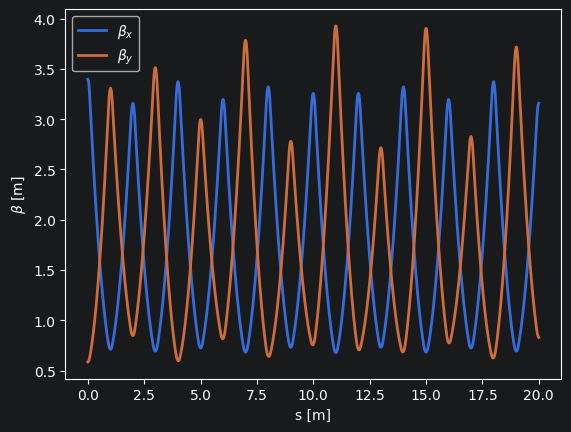

In [10]:
plt.plot(T[:,0], T[:,1], linewidth=2, label=r'$\beta_x$')
plt.plot(T[:,0], T[:,2], linewidth=2, label=r'$\beta_y$')
plt.legend()
plt.xlabel('s [m]')
plt.ylabel(r'$\beta$ [m]')
plt.show()

# Now we can match the Twiss parameters to be periodic
## Start with defining a merit function
This function returns zero when the initial and final beta functions are equal and the initial and final alpha functions are equal:
\begin{align*}
\chi^{2}= & \left(\beta_{x,\text{ final}}-\beta_{x,\text{ initial}}\right)^{2}+\cdots\\
 & \left(\beta_{y,\text{ final}}-\beta_{y,\text{ initial}}\right)^{2}+\cdots\\
 & \left(\alpha_{x,\text{ final}}-\alpha_{x,\text{ initial}}\right)^{2}+\cdots\\
 & \left(\alpha_{y,\text{ final}}-\alpha_{y,\text{ initial}}\right)^{2}
\end{align*}

Here the beta residuals are expressed in metres and the alpha residuals are dimensionless. This simple merit keeps the original tutorial's weighting; for a real matching specification, divide each residual by its required tolerance.

In [11]:
def match_Twiss(twiss, FODO, noise=0.0, return_residuals=False):

    beta_x = twiss[0] # m
    beta_y = twiss[1] # m
    alpha_x = twiss[2]
    alpha_y = twiss[3]

    # Create a bunch with initial beta_x and beta_y from 'twiss'
    Twiss = rft.Bunch6d_twiss()
    Twiss.emitt_x = 0.001 # mm.mrad, normalized emittances
    Twiss.emitt_y = 0.001 # mm.mrad
    Twiss.beta_x = beta_x # m
    Twiss.beta_y = beta_y # m
    Twiss.alpha_x = alpha_x #
    Twiss.alpha_y = alpha_y #

    # Create the bunch
    B0 = rft.Bunch6d_QR (mass, population, charge, Pc, Twiss, 1000)

    # Perform tracking
    B1 = FODO.track(B0)
    I1 = B1.get_info()

    # Final minus initial Twiss parameters, plus an optional measurement error
    residuals = np.array([I1.beta_x - beta_x,
                          I1.beta_y - beta_y,
                          I1.alpha_x - alpha_x,
                          I1.alpha_y - alpha_y])
    residuals += np.random.normal(scale=noise, size=4)
    return residuals if return_residuals else np.sum(residuals ** 2) # M = merit function

## An initial guess from two test particles

Before running the optimizer, we calculate the Twiss parameters that repeat after one FODO cell. This gives us an independent reference for checking the optimization result.

In linear, uncoupled optics, a particle's final position and angle depend on its starting position and angle:

$$
\begin{aligned} x_f &= R_{11}x_0 + R_{12}x'_0, \\ x'_f &= R_{21}x_0 + R_{22}x'_0. \end{aligned}
$$

In matrices below, positions are in **mm** and angles in **mrad**.

**Particle 1 - position only:** $x_0=1\,\mathrm{mm}$ and $x'_0=0$.

$$
\begin{pmatrix}x_f^{(1)}\\x_f^{\prime(1)}\end{pmatrix} = \begin{pmatrix}R_{11}&R_{12}\\R_{21}&R_{22}\end{pmatrix}\begin{pmatrix}1\\0\end{pmatrix} = \begin{pmatrix}R_{11}\cdot1+R_{12}\cdot0\\R_{21}\cdot1+R_{22}\cdot0\end{pmatrix} = \begin{pmatrix}R_{11}\\R_{21}\end{pmatrix}.
$$

The zero angle removes the second column's values. Tracking gives the first column of $R$.

**Particle 2 - angle only:** $x_0=0$ and $x'_0=1\,\mathrm{mrad}$.

$$
\begin{pmatrix}x_f^{(2)}\\x_f^{\prime(2)}\end{pmatrix} = \begin{pmatrix}R_{11}&R_{12}\\R_{21}&R_{22}\end{pmatrix}\begin{pmatrix}0\\1\end{pmatrix} = \begin{pmatrix}R_{11}\cdot0+R_{12}\cdot1\\R_{21}\cdot0+R_{22}\cdot1\end{pmatrix} = \begin{pmatrix}R_{12}\\R_{22}\end{pmatrix}.
$$

The zero position removes the first column's values. Tracking gives the second column of $R$.

We repeat this for $y$: **four test particles in total**. They determine the lattice response, so we do not need to estimate it from a large bunch.

For this stable FODO cell, $R$ gives the phase advance $\mu$ and the periodic Twiss parameters:

$$
\cos\mu=\frac{R_{11}+R_{22}}{2},\qquad \beta=\frac{R_{12}}{\sin\mu},\qquad \alpha=\frac{R_{11}-R_{22}}{2\sin\mu}.
$$

We use this solution only as a reference. The optimizers still evaluate the matching merit by tracking a 1000-particle bunch.

In [12]:
bx = np.array([
    [1.0, 0.0, 0.0, 0.0, 0.0, Pc],
    [0.0, 1.0, 0.0, 0.0, 0.0, Pc],
], dtype=float)

bunch_x = rft.Bunch6d(mass, 0.0, charge, bx)
tracked_x = FODO.track(bunch_x)
phase_space_x = np.asarray(tracked_x.get_phase_space("%x %xp"), dtype=float)

R11 = float(phase_space_x[0, 0])
R12 = float(phase_space_x[1, 0])
R21 = float(phase_space_x[0, 1])
R22 = float(phase_space_x[1, 1])

by = np.array([
    [0.0, 0.0, 1.0, 0.0, 0.0, Pc],
    [0.0, 0.0, 0.0, 1.0, 0.0, Pc],
], dtype=float)

bunch_y = rft.Bunch6d(mass, 0.0, charge, by)
tracked_y = FODO.track(bunch_y)
phase_space_y = np.asarray(tracked_y.get_phase_space("%y %yp"), dtype=float)

R33 = float(phase_space_y[0, 0])
R34 = float(phase_space_y[1, 0])
R43 = float(phase_space_y[0, 1])
R44 = float(phase_space_y[1, 1])

Rx = np.array([[R11, R12],
               [R21, R22]])
Ry = np.array([[R33, R34],
               [R43, R44]])

def periodic_Twiss(R):
    mu = np.arccos((R[0,0] + R[1,1]) / 2)
    return R[0,1] / np.sin(mu), (R[0,0] - R[1,1]) / (2 * np.sin(mu)), np.rad2deg(mu)

beta_x0, alpha_x0, mu_x = periodic_Twiss(Rx)
beta_y0, alpha_y0, mu_y = periodic_Twiss(Ry)
exact_twiss = np.array([beta_x0, beta_y0, alpha_x0, alpha_y0])
merit_floor = match_Twiss(exact_twiss, FODO)

print(f"Phase advance per cell: mu_x = {mu_x:.1f} deg, mu_y = {mu_y:.1f} deg")
print(f"Solution: beta_x = {beta_x0:.4f} m, beta_y = {beta_y0:.4f} m, alpha_x = {alpha_x0:.1e}, alpha_y = {alpha_y0:.1e}")
print(f"Merit of the exact solution with a 1000-particle bunch: {merit_floor:.1e}")

Phase advance per cell: mu_x = 82.3 deg, mu_y = 82.3 deg
Solution: beta_x = 3.2715 m, beta_y = 0.7049 m, alpha_x = -1.4e-16, alpha_y = -1.4e-17
Merit of the exact solution with a 1000-particle bunch: 7.0e-04


## Let Xopt choose the next trial

Xopt needs three things: the **variables and their bounds**, an **evaluator** that runs our calculation, and a **generator** that chooses new trials. We use expected improvement: it learns from previous results to balance searching uncertain regions with improving the best match. Xopt handles the Bayesian model internally.

The evaluator receives a dictionary of named inputs and returns a dictionary of results. This small wrapper lets us reuse `match_Twiss` unchanged.

In [13]:
from xopt import Xopt
from xopt.vocs import VOCS
from xopt.evaluator import Evaluator
from xopt.generators.bayesian import ExpectedImprovementGenerator
from xopt.generators.bayesian.objectives import CustomXoptObjective

parameter_names = ["beta_x", "beta_y", "alpha_x", "alpha_y"]
residual_names = ["res_beta_x", "res_beta_y", "res_alpha_x", "res_alpha_y"]

# Variable and Objective Constraint Settings: the SciPy bounds, with beta > 0.
# There is no objective: Xopt models the four residuals ("observables").
vocs = VOCS(
    variables={
        "beta_x": [0.01, 10],  # m
        "beta_y": [0.01, 10],  # m
        "alpha_x": [-5, 5],
        "alpha_y": [-5, 5],
    },
    observables=residual_names,
)


class SumOfSquares(CustomXoptObjective):
    def forward(self, samples, X=None):
        return -(samples ** 2).sum(dim=-1)

## Run the optimization

First evaluate the thin-lens guess and a few random trials. Then each `X.step()` proposes one new set of Twiss parameters, tracks the beam, and stores the four residuals in `X.data`.

In [14]:
initial_guess = dict(zip(parameter_names, [Twiss.beta_x, Twiss.beta_y, 0.0, 0.0]))
n_random = 7
n_steps = 40

def xopt_matching(noise=0.0):
    def evaluate_matching(inputs):
        twiss = [inputs[name] for name in parameter_names]
        return dict(zip(residual_names, match_Twiss(twiss, FODO, noise, return_residuals=True)))

    X = Xopt(
        vocs=vocs,
        evaluator=Evaluator(function=evaluate_matching),
        generator=ExpectedImprovementGenerator(vocs=vocs, custom_objective=SumOfSquares(vocs)),
    )
    X.evaluate_data([initial_guess])
    X.random_evaluate(n_random, seed=42)
    for step in range(n_steps):
        X.step()

    # Select the best point actually evaluated, keeping the original parameter order.
    merit = (X.data[residual_names] ** 2).sum(axis=1)
    best_twiss = X.data.loc[merit.idxmin(), parameter_names].to_numpy(dtype=float)
    return best_twiss, merit.to_numpy(), X.data[parameter_names].to_numpy(dtype=float)


start_time = perf_counter()
matched_twiss, merit_history, _ = xopt_matching()
print(f"Xopt time: {perf_counter() - start_time:.3f} s")
print("Matched [beta_x, beta_y, alpha_x, alpha_y]:", matched_twiss)
print(f"Merit: {merit_history[0]:.6g} -> {merit_history.min():.6g}")
print(f"Total tracking evaluations: {len(merit_history)}")
print("Difference from the exact solution (test particles):", np.round(matched_twiss - exact_twiss, 4))

Xopt time: 172.097 s
Matched [beta_x, beta_y, alpha_x, alpha_y]: [3.27868644e+00 7.06949732e-01 2.00456337e-03 8.62090283e-03]
Merit: 0.135161 -> 1.89678e-05
Total tracking evaluations: 48
Difference from the exact solution (test particles): [0.0072 0.002  0.002  0.0086]


### Comparison with SciPy

The iteration budget is not a convergence guarantee. For comparison, we repeat the SciPy matching of pyTutorial_04 with the same bounds and initial guess, recording every tracking run. The random initialization is seeded; Bayesian proposals can still vary between runs.

The dashed line is the merit of the exact solution: below it, an optimizer only fits the statistical error of the 1000-particle bunch. The relevant question is therefore how many tracking runs each method needs to reach this line.

In [15]:
from scipy.optimize import minimize

scipy_bounds = [(0.01, 10), (0.01, 10), (-5, 5), (-5, 5)]

def scipy_matching(noise=0.0):
    history = []
    points = []
    def merit(twiss):
        history.append(match_Twiss(twiss, FODO, noise))
        points.append(twiss.copy())
        return history[-1]
    result = minimize(merit, [initial_guess[name] for name in parameter_names], bounds=scipy_bounds)
    return result.x, np.array(history), np.array(points)

start_time = perf_counter()
scipy_twiss, scipy_history, _ = scipy_matching()
print(f"SciPy time: {perf_counter() - start_time:.3f} s")
print(f"SciPy: best merit {scipy_history.min():.3g} after {len(scipy_history)} tracking evaluations")

SciPy time: 0.072 s
SciPy: best merit 1.42e-11 after 45 tracking evaluations


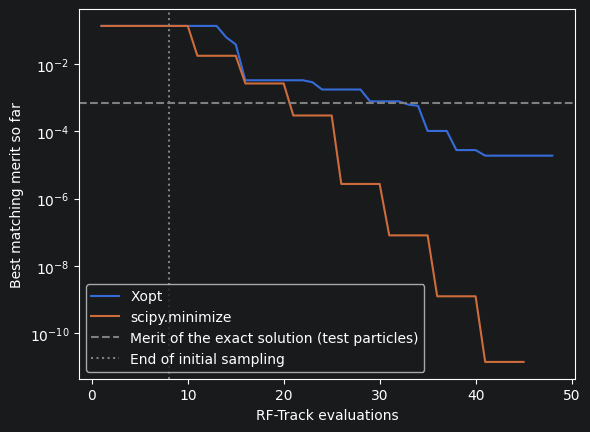

In [16]:
plt.semilogy(np.arange(1, len(merit_history) + 1), np.minimum.accumulate(merit_history), label="Xopt")
plt.semilogy(np.arange(1, len(scipy_history) + 1), np.minimum.accumulate(scipy_history), label="scipy.minimize")
plt.axhline(merit_floor, color="grey", linestyle="--", label="Merit of the exact solution (test particles)")
plt.axvline(n_random + 1, color="grey", linestyle=":", label="End of initial sampling")
plt.xlabel("RF-Track evaluations")
plt.ylabel("Best matching merit so far")
plt.legend(loc="lower left")
plt.show()

Let's create a beam with the matched beta functions

In [17]:
Twiss.beta_x = matched_twiss[0]
Twiss.beta_y = matched_twiss[1]
Twiss.alpha_x = matched_twiss[2]
Twiss.alpha_y = matched_twiss[3]

# Create the bunch
B0 = rft.Bunch6d_QR (mass, population, charge, Pc, Twiss, 1000)

In [18]:
L.set_tt_nsteps(1000)
B1 = L.track(B0)

In [19]:
T = L.get_transport_table('%S %beta_x %beta_y %emitt_x %emitt_y %sigma_x %sigma_y')

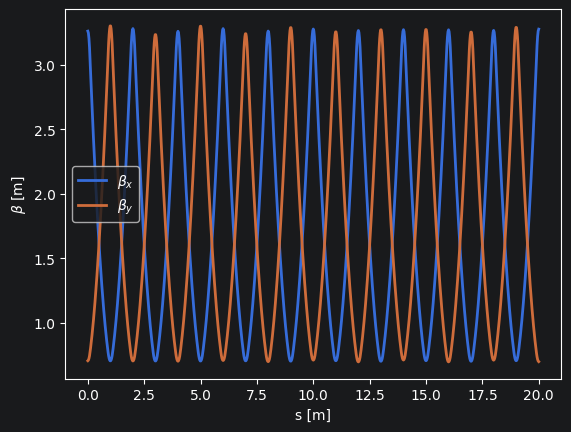

In [20]:
plt.plot(T[:,0], T[:,1], linewidth=2, label=r'$\beta_x$')
plt.plot(T[:,0], T[:,2], linewidth=2, label=r'$\beta_y$')
plt.legend()
plt.xlabel('s [m]')
plt.ylabel(r'$\beta$ [m]')
plt.show()

# Why Bayesian optimization? Noisy measurements

On a real accelerator the Twiss parameters are measured, and every measurement has an error. We imitate this with `noise = 0.01`: a random error of 1 cm on each beta function and of 0.01 on each alpha function, different at every evaluation.

`scipy.minimize` estimates gradients from tiny finite differences. The Gaussian process instead averages the noise over many evaluations. The merit is now noisy too, so we judge both results by their distance from the exact solution computed with the test particles.

In [21]:
noise = 0.01

start_time = perf_counter()
xopt_twiss_noisy, xopt_history_noisy, xopt_points_noisy = xopt_matching(noise)
print(f"Xopt time (noise={noise}): {perf_counter() - start_time:.3f} s")
start_time = perf_counter()
scipy_twiss_noisy, scipy_history_noisy, scipy_points_noisy = scipy_matching(noise)
print(f"SciPy time (noise={noise}): {perf_counter() - start_time:.3f} s")

print("Difference from the exact solution [beta_x, beta_y, alpha_x, alpha_y]:")
print("  Xopt:            ", np.round(xopt_twiss_noisy - exact_twiss, 4), f"after {len(xopt_history_noisy)} evaluations")
print("  SciPy:           ", np.round(scipy_twiss_noisy - exact_twiss, 4), f"after {len(scipy_history_noisy)} evaluations")

Xopt time (noise=0.01): 174.825 s
SciPy time (noise=0.01): 0.148 s
Difference from the exact solution [beta_x, beta_y, alpha_x, alpha_y]:
  Xopt:             [0.0057 0.0032 0.0034 0.0089] after 48 evaluations
  SciPy:            [ 0.1427 -0.1192  0.      0.    ] after 100 evaluations


### Conclusions

Without noise, and with a simulation this cheap, SciPy is actually the better choice here. It needs a similar number of tracking runs to reach the statistical precision of the 1000-particle bunch. Bayesian optimization is better when:

* each evaluation is expensive (a measurement on the machine, or a long simulation),
* the measurement is noisy,
* there is no good initial guess.
As you can see, with added noise, scipy behaves in a worse way, with a larger cost of evaluation.
One could play with the noise to see the advantage of BO.

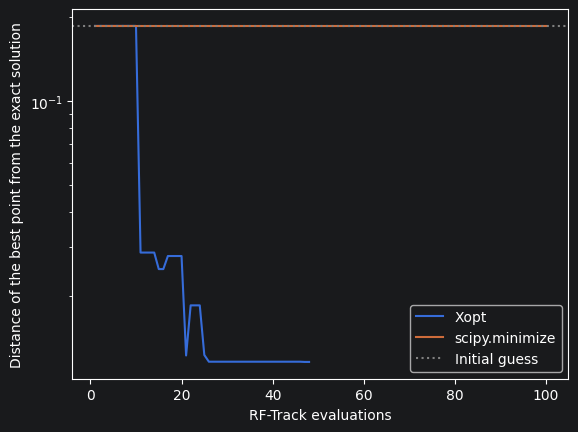

In [22]:
def best_distance(points, merits):
    # Distance from the exact solution of the best point so far
    return [np.linalg.norm(points[np.argmin(merits[:k])] - exact_twiss) for k in range(1, len(merits) + 1)]

plt.semilogy(range(1, len(xopt_history_noisy) + 1), best_distance(xopt_points_noisy, xopt_history_noisy), label="Xopt")
plt.semilogy(range(1, len(scipy_history_noisy) + 1), best_distance(scipy_points_noisy, scipy_history_noisy), label="scipy.minimize")
plt.axhline(np.linalg.norm(np.array([initial_guess[name] for name in parameter_names]) - exact_twiss), color="grey", linestyle=":", label="Initial guess")
plt.xlabel("RF-Track evaluations")
plt.ylabel("Distance of the best point from the exact solution")
plt.legend()
plt.show()

# When to use Xopt and Bayesian optimization

Bayesian optimization pays off when every evaluation is expensive: a measurement on the machine or a long simulation, often noisy, with a moderate number of variables (typically up to about 20) and no good model or initial guess. E.g optimizing the transmission.

For not many degrees of freedom and a noise-free problem with a good initial guess, like the noise-free matching above, a local optimizer such as `scipy.minimize` is faster and more precise.

# Exercises

## Exercise 1 — Explore the evaluation budget

Try different values of `n_steps` and different numbers of initial random trials. Rerun from the cell that creates `X` for each fresh optimization. Compare the best merit and the number of RF-Track evaluations. How close is the result to the original SciPy example?

Widen the variable bounds and repeat. Why can a physically informed search range help?

Finally, add a penalty $\lambda(\beta_x^2+\beta_y^2)$ to the merit and investigate the compromise between periodicity and beam size.

In [23]:
# Your solution